# Are apparent timing patterns stable or driven by a few pitchers?

Use whole-pitcher validation resampling, joint temporal contrast bands, six whole-pitcher training refits, event-concentration diagnostics and a shared-event sensitivity. These checks are distinct from one another.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
while not (ROOT/'src/injury_analysis').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_temporal_common import OUT, CACHE, read_table
pd.set_option('display.max_columns',24)
def show(name,n=30): display(read_table(name).head(n))
def plot(name): display(Image(filename=str(OUT/'figures'/(name+'.png')),width=1150))


In [2]:
from src.injury_analysis.ucl_temporal_analysis import analyze_partition, run_refits
analyze_partition('validation'); run_refits()
show('candidate_ranking',n=15)
display(json.loads((OUT/'development_freeze.json').read_text())['development_summary'])

Verified checkpoint: uncertainty_validation


Verified checkpoint: training_refits


,family,mean_ablation_lift,positive_intervals,lower_bound_positive_intervals,mean_permutation_ap_loss
0,Velocity,1.164444,4,0,0.002656
1,Pitcher background and experience,0.844173,3,0,0.002708
2,Pitch movement,0.834963,3,0,0.001878
3,Release position and variability,0.424561,3,0,0.002316
4,Workload and rest,0.203554,3,2,-0.001200
5,Role and recent starts,0.015758,1,1,0.001246
6,Extension,-0.028261,2,0,-0.000650
7,Appearance performance,-0.047230,2,0,0.000859
8,Spin,-0.196709,1,0,0.002011
9,Location and strike fractions,-0.284671,2,0,0.001533


{'families': 11,
 'intervals': 4,
 'positive_ablation_cells': 24,
 'ablation_pointwise_lower_above_zero': 3,
 'simultaneous_temporal_contrasts_excluding_zero': 0}

The candidate nomination rule uses validation only: mean ablation AP loss divided by interval prevalence. Candidates are narrow follow-up hypotheses, not established timing-specific mechanisms. The refits are conditional on nomination rather than a nested selection experiment.

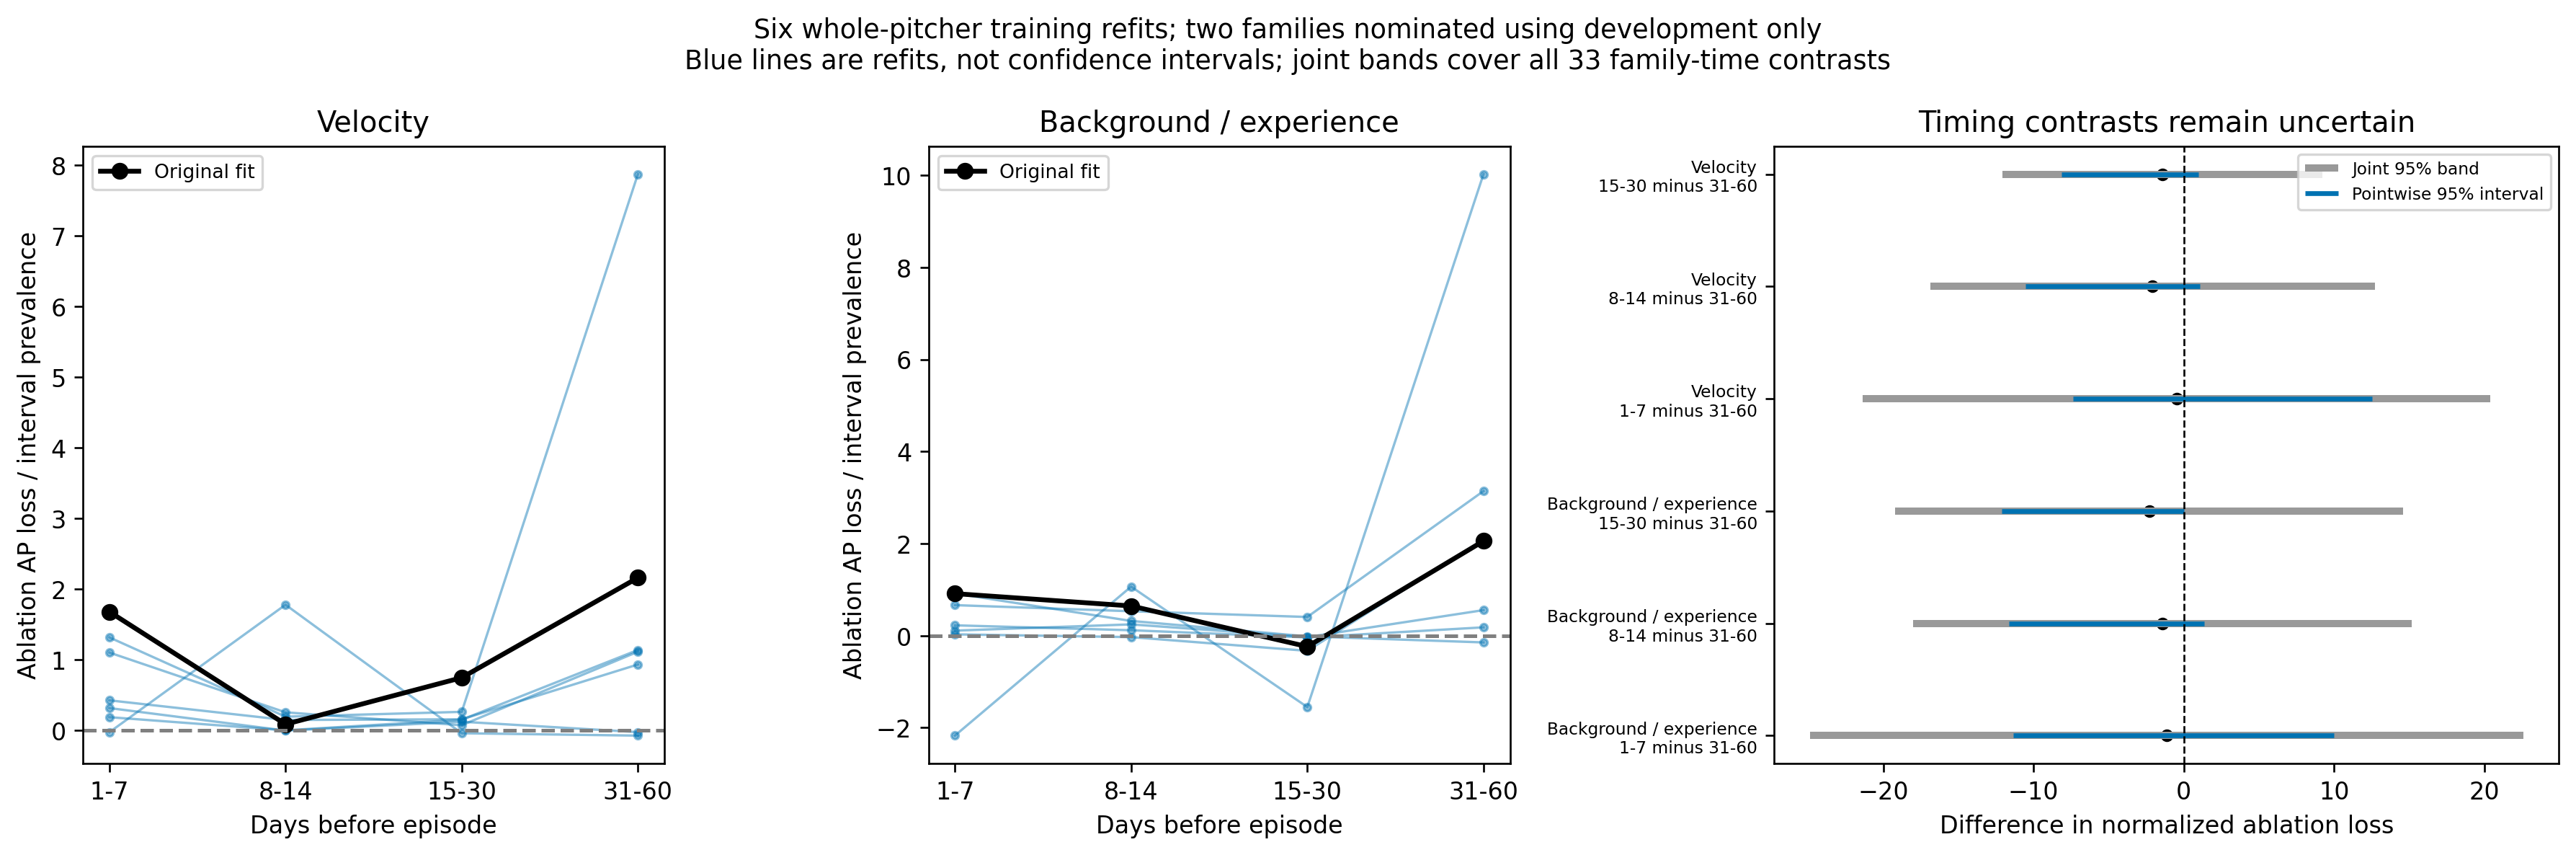

,partition,family,contrast,ablation_lift_difference,ci_low,ci_high,bootstrap_positive_fraction,valid_replicates,simultaneous_low,simultaneous_high,simultaneous_critical_value,comparisons
0,validation,Appearance performance,1-7 minus 31-60,0.249128,-0.290839,4.622003,0.820000,300,-5.622399,6.120654,4.713349,33
1,validation,Appearance performance,8-14 minus 31-60,0.303595,-0.357386,1.834771,0.790000,300,-2.093634,2.700824,4.713349,33
2,validation,Appearance performance,15-30 minus 31-60,0.246466,-0.269020,1.495121,0.806667,300,-1.847094,2.340026,4.713349,33
3,validation,Extension,1-7 minus 31-60,0.027931,-2.325404,9.516204,0.596667,300,-13.848915,13.904778,4.713349,33
4,validation,Extension,8-14 minus 31-60,0.137687,-1.867534,6.218445,0.490000,300,-9.851086,10.126460,4.713349,33
5,validation,Extension,15-30 minus 31-60,0.114181,-2.681743,6.242984,0.470000,300,-10.178583,10.406944,4.713349,33
6,validation,Location and strike fractions,1-7 minus 31-60,1.093898,-0.145223,9.104013,0.943333,300,-10.854710,13.042505,4.713349,33
7,validation,Location and strike fractions,8-14 minus 31-60,0.756425,-2.000397,4.993889,0.693333,300,-7.460735,8.973585,4.713349,33
8,validation,Location and strike fractions,15-30 minus 31-60,1.331760,-0.081106,5.820591,0.900000,300,-6.954125,9.617645,4.713349,33
9,validation,Pitch mix and pitch-type counts,1-7 minus 31-60,-0.844292,-10.775955,2.826385,0.246667,300,-17.141443,15.452860,4.713349,33


In [3]:
plot('04_temporal_stability')
show('temporal_contrasts_validation',n=33)

The joint bands cover all 33 predeclared family contrasts (each nearer interval versus 31–60 days). None excludes zero. Two pointwise role contrasts are insufficient to declare a longer-horizon role signal after considering the full contrast family.

In [4]:
show('training_refit_family_losses',n=25)
show('role_composition_validation',n=8)

,interval,refit,family,ablation_ap_loss,ablation_lift_loss,standalone_lift
0,1-7,0,Velocity,0.000729,0.312077,4.117175
1,1-7,0,Pitcher background and experience,0.000524,0.224546,1.726909
2,1-7,1,Velocity,-0.000072,-0.030768,2.587336
3,1-7,1,Pitcher background and experience,-0.005070,-2.171142,2.114451
4,1-7,2,Velocity,0.003066,1.312852,3.789767
5,1-7,2,Pitcher background and experience,0.001549,0.663202,1.724982
6,1-7,3,Velocity,0.000428,0.183160,6.063972
7,1-7,3,Pitcher background and experience,0.000066,0.028454,1.763704
8,1-7,4,Velocity,0.000984,0.421518,10.808436
9,1-7,4,Pitcher background and experience,0.000256,0.109436,2.290382


,partition,interval,outcome,rows,pitchers,starter_fraction,median_prior_appearances,median_age
0,validation,1-7,positive,52,25,0.538462,79.5,27.782911
1,validation,1-7,comparison,22217,749,0.243732,112.0,29.246323
2,validation,8-14,positive,28,20,0.428571,78.0,27.498169
3,validation,8-14,comparison,22241,750,0.244189,112.0,29.246323
4,validation,15-30,positive,58,17,0.500000,78.5,27.569355
5,validation,15-30,comparison,22211,750,0.243753,113.0,29.249061
6,validation,31-60,positive,51,10,0.450980,104.0,28.047119
7,validation,31-60,comparison,22218,750,0.243946,112.0,29.246323


In [5]:
c=read_table('event_ap_contributions_validation')
for name,h in [('Only | Velocity','1-7'),('Only | Workload and rest','31-60')]:
    display(c.loc[c.model.eq(name)&c.interval.eq(h)].nlargest(4,'fraction_total_ap'))
i=read_table('pitcher_influence_validation')
display(i.loc[(i.model.eq('Only | Velocity')&i.interval.eq('1-7'))|(i.model.eq('Only | Workload and rest')&i.interval.eq('31-60'))].sort_values('ap_drop',ascending=False).head(8))

,pitcher_id,dynamic_next_event_id,positive_rows,ap_contribution,fraction_total_ap,partition,interval,model
259,642585,8c945a320728dd144f1dccaa07472b52,4,0.020069,0.806307,validation,1-7,Only | Velocity
271,669622,fae28b12535c521d62c9956ae54987a5,4,0.000944,0.037917,validation,1-7,Only | Velocity
250,448281,c3db3b49bf107cb0ee0ecbb4042dab32,4,0.000437,0.017559,validation,1-7,Only | Velocity
267,663978,dafa10ed89d3cf696b69a68ac6adc2d2,2,0.000350,0.014082,validation,1-7,Only | Velocity


,pitcher_id,dynamic_next_event_id,positive_rows,ap_contribution,fraction_total_ap,partition,interval,model
1172,669160,b8c709ba2285198a20ea9de37551445f,4,0.011505,0.693574,validation,31-60,Only | Workload and rest
1169,663432,e4eec2cb47485f3540f6cd1613d2592f,10,0.001733,0.104490,validation,31-60,Only | Workload and rest
1167,642585,8c945a320728dd144f1dccaa07472b52,10,0.001244,0.075000,validation,31-60,Only | Workload and rest
1168,656876,aecc78a67612cc72750dbfc5f3a42594,2,0.000378,0.022796,validation,31-60,Only | Workload and rest


,partition,interval,model,pitcher_id,original_ap,ap_without_pitcher,ap_drop
259,validation,1-7,Only | Velocity,642585,0.024889,0.004029,0.020860
1172,validation,31-60,Only | Workload and rest,669160,0.016589,0.003970,0.012618
1168,validation,31-60,Only | Workload and rest,656876,0.016589,0.016447,0.000142
271,validation,1-7,Only | Velocity,669622,0.024889,0.024913,-0.000024
1173,validation,31-60,Only | Workload and rest,686753,0.016589,0.016834,-0.000246
255,validation,1-7,Only | Velocity,608566,0.024889,0.025138,-0.000249
267,validation,1-7,Only | Velocity,663978,0.024889,0.025209,-0.000320
266,validation,1-7,Only | Velocity,663753,0.024889,0.025238,-0.000349


One event supplies about 81% of near-term velocity-family AP, and another supplies about 69% of longer-horizon workload-family AP. These cases remain in the primary cohort. The diagnostics constrain interpretation of the visually attractive temporal ordering.

In [6]:
s=read_table('shared_event_sensitivity_validation')
display(s.loc[s.model.isin(['Profile','Departure','Full union','Only | Velocity','Only | Workload and rest'])])

,partition,interval,model,rows,shared_events,positive_rows,prevalence,pr_lift,average_precision,roc_auc
0,validation,1-7,Full union,22204,10,22,0.000991,10.527897,0.010431,0.700908
19,validation,1-7,Only | Velocity,22204,10,22,0.000991,48.275007,0.047831,0.545053
21,validation,1-7,Only | Workload and rest,22204,10,22,0.000991,1.391408,0.001379,0.589364
24,validation,1-7,Profile,22204,10,22,0.000991,1.440223,0.001427,0.580169
25,validation,1-7,Departure,22204,10,22,0.000991,2.600404,0.002577,0.529670
28,validation,8-14,Full union,22204,10,13,0.000585,3.268494,0.001914,0.582145
47,validation,8-14,Only | Velocity,22204,10,13,0.000585,1.402202,0.000821,0.544431
49,validation,8-14,Only | Workload and rest,22204,10,13,0.000585,2.219190,0.001299,0.624252
52,validation,8-14,Profile,22204,10,13,0.000585,2.319192,0.001358,0.711116
53,validation,8-14,Departure,22204,10,13,0.000585,1.171881,0.000686,0.496255


The shared-event sensitivity evaluates only UCL events represented in all four intervals, keeping observed comparison rows and saved models. It is retrospective and small. It tests whether interval composition may contribute to apparent heterogeneity; it is not a replacement cohort or a new fit.

In [7]:
show('family_matrix_test',n=16)
show('reference_temporal_contrasts_test',n=10)

,partition,interval,family,fields,rows,positive_rows,represented_events,prevalence,standalone_ap,standalone_lift,ablation_ap_loss,ablation_lift_loss,...,ablation_lift_ci_low,ablation_lift_ci_high,ablation_lift_bootstrap_positive_fraction,ablation_lift_valid_replicates,permutation_ci_low,permutation_ci_high,permutation_bootstrap_positive_fraction,permutation_valid_replicates,warning_ci_low,warning_ci_high,warning_bootstrap_positive_fraction,warning_valid_replicates
0,test,1-7,Appearance performance,4,22782,51,28,0.002239,0.002498,1.115984,0.002426,1.083556,...,-0.656716,8.123539,0.746667,300,-0.011010,0.012764,0.390000,300,-0.071429,0.068182,0.316667,300
1,test,1-7,Extension,8,22782,51,28,0.002239,0.003341,1.492550,-0.000423,-0.188849,...,-2.468961,1.219796,0.363333,300,-0.012133,0.005128,0.330000,300,-0.113636,0.045455,0.173333,300
2,test,1-7,Location and strike fractions,12,22782,51,28,0.002239,0.002594,1.158877,-0.013752,-6.143266,...,-22.282169,0.244053,0.100000,300,-0.026656,0.000042,0.030000,300,-0.070640,0.048780,0.336667,300
3,test,1-7,Pitch mix and pitch-type counts,14,22782,51,28,0.002239,0.002851,1.273427,0.002646,1.181947,...,-4.486296,14.676803,0.656667,300,-0.011678,0.040346,0.753333,300,-0.071429,0.068182,0.316667,300
4,test,1-7,Pitch movement,9,22782,51,28,0.002239,0.003370,1.505229,0.001149,0.513291,...,-9.880068,5.151698,0.753333,300,-0.001950,0.016400,0.780000,300,-0.119048,0.000000,0.000000,300
5,test,1-7,Pitcher background and experience,7,22782,51,28,0.002239,0.003904,1.744151,0.006861,3.065045,...,0.244742,16.120754,0.996667,300,0.000645,0.048056,0.990000,300,-0.070640,0.048780,0.336667,300
6,test,1-7,Release position and variability,19,22782,51,28,0.002239,0.002653,1.184953,0.006015,2.686750,...,-1.305145,17.925629,0.846667,300,-0.006605,0.023436,0.596667,300,-0.097561,0.047619,0.150000,300
7,test,1-7,Role and recent starts,4,22782,51,28,0.002239,0.005823,2.601021,0.004694,2.096929,...,-1.558487,16.046166,0.816667,300,0.001225,0.048944,1.000000,300,0.000000,0.073171,0.640000,300
8,test,1-7,Spin,8,22782,51,28,0.002239,0.003075,1.373753,0.005170,2.309636,...,-1.524501,17.170518,0.780000,300,-0.003142,0.036895,0.820000,300,-0.067462,0.071429,0.306667,300
9,test,1-7,Velocity,13,22782,51,28,0.002239,0.002650,1.183911,-0.001982,-0.885376,...,-11.804723,12.363350,0.373333,300,-0.008758,0.038294,0.790000,300,-0.071429,0.000000,0.000000,300


,partition,model,contrast,lift_difference,ci_low,ci_high,bootstrap_positive_fraction,valid_replicates
0,test,Departure,1-7 minus 31-60 PR lift,0.270672,-1.178155,2.898828,0.656667,300
1,test,Profile,1-7 minus 31-60 PR lift,0.786811,-0.009545,2.159315,0.973333,300
2,test,Background,1-7 minus 31-60 PR lift,0.573204,-1.131721,2.244334,0.843333,300
3,test,Previous 62,1-7 minus 31-60 PR lift,7.011875,1.827783,28.543996,1.000000,300
4,test,Stable 62,1-7 minus 31-60 PR lift,5.516269,-1.194587,26.575313,0.950000,300


2024–2025 is previously examined exploratory transfer. It cannot be used to revise the candidate families, interval boundaries or model settings. Null, opposing and unstable results remain in the outputs.